# FlowCast modelling and evaluation

This notebook reads actual saved model results. Training is performed by the source modules so that the notebook and dashboard use the same pipeline. No scores or predictions are entered by hand.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
import pandas as pd
from IPython.display import display, Image
from src.features import load_dataset
from src.utils import ROOT
import json
display(pd.read_csv(ROOT / 'reports/model_selection.csv').round(4))
print(json.dumps(json.loads((ROOT / 'reports/split_counts.json').read_text()), indent=2))

,task,model,selection_score,cv_mean,candidate,speed_validation_rmse,travel_validation_rmse
0,flow,Numpy GD,100.3064,103.9796,1,5.2052,1.4588
1,flow,Linear Regression,100.2373,105.3957,0,5.1752,1.4833
2,flow,Decision Tree,59.1558,76.0397,1,3.7551,1.1045
3,flow,Random Forest,55.3820,70.6363,1,3.5759,1.0900
4,flow,XGBoost,56.5263,67.2689,1,3.4451,1.0948
5,congestion,Decision Tree,0.7396,0.7032,1,NaN,NaN
6,congestion,Random Forest,0.7532,0.7195,1,NaN,NaN
7,congestion,XGBoost,0.7590,0.7344,1,NaN,NaN
8,congestion,SVM,0.6656,0.6385,0,NaN,NaN
9,accident,Decision Tree,0.5227,0.5671,0,NaN,NaN


{
  "train": 473484,
  "validation": 104433,
  "test": 104356,
  "boundary_excluded": 463,
  "feature_or_target_excluded": 42064
}


## Time-aware model selection

Training ends on 15 April 2025. Validation ends on 8 May. Later origins form the test set. Two expanding training folds tune parameters, with a gap for the longest horizon. The first validation half selects models; the later half calibrates uncertainty. Test data never selects a model.

In [2]:
cv = pd.read_csv(ROOT / 'reports/cv_results.csv')
display(cv.groupby(['task', 'model', 'candidate']).score.agg(['mean', 'std']).round(4))
display(pd.read_csv(ROOT / 'reports/model_comparison.csv').round(4))

mean      std
task       model             candidate                   
accident   Decision Tree     0            0.5671   0.0155
                             1            0.5388   0.0066
           Random Forest     0            0.5713   0.0120
                             1            0.5630   0.0017
           SVM               0            0.6057   0.0119
                             1            0.6057   0.0119
           XGBoost           0            0.6011   0.0103
                             1            0.5937   0.0028
congestion Decision Tree     0            0.6884   0.0318
                             1            0.7032   0.0437
           Random Forest     0            0.7082   0.0423
                             1            0.7195   0.0401
           SVM               0            0.6385   0.0366
                             1            0.6384   0.0367
           XGBoost           0            0.7261   0.0414
                             1            0.7344   0.0431
flow       Decision Tree     0           87.6555  13.1275
                             1           76.0397  17.0793
           Linear Regression 0          105.3957   6.8581
           Numpy GD          0          105.6275   2.2772
                             1          103.9796   2.3580
           Random Forest     0           74.4983  14.4576
                             1           70.6363  16.5735
           XGBoost           0           72.9484  11.1859
                             1           67.2689  15.1155

,model,task,horizon,n,rmse,mae,mape,r2,zero_targets,precision,recall,f1,macro_f1,accuracy,roc_auc,brier
0,Numpy GD,traffic_volume,1,26124,96.2216,74.0768,22.0212,0.8886,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Numpy GD,traffic_volume,2,26100,95.4023,72.3651,21.3708,0.8905,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Numpy GD,traffic_volume,3,26078,103.0578,76.7553,22.1117,0.8722,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Numpy GD,traffic_volume,4,26054,116.6019,86.5204,24.1712,0.8365,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Numpy GD,avg_speed,1,26124,4.9814,3.8385,12.5591,0.8199,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,SVM,accident,4,26054,NaN,NaN,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.4976,0.9903,0.6045,0.0096
92,GRU,traffic_volume,1,26124,61.9687,43.1387,10.6277,0.9538,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
93,GRU,congestion,1,26124,NaN,NaN,NaN,NaN,NaN,0.7544,0.7587,0.7564,0.7564,0.8643,NaN,NaN
94,BiLSTM,traffic_volume,1,26124,63.2537,42.8110,9.9563,0.9519,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Explicit mathematics and recurrent learning

The NumPy baseline uses MSE and the gradient 2 Xᵀ(XW − y) / n. GRU and BiLSTM models start with random weights and use scaled MSE plus congestion cross-entropy. Dropout, weight decay, early stopping and learning-rate reduction control overfitting. The bidirectional model only reads the past input sequence.

,epoch,mse_scaled
0,1,0.632331
179,180,0.169191


,model,trial,sequence_length,hidden_size,layers,dropout,learning_rate,batch_size,best_validation_loss,validation_rmse,epochs_run
0,GRU,0,8,32,1,0.15,0.0010,512,0.123332,61.852961,18
1,GRU,1,12,48,2,0.20,0.0015,256,0.119197,60.064182,18
2,BiLSTM,0,12,48,2,0.20,0.0015,256,0.119996,61.018749,18


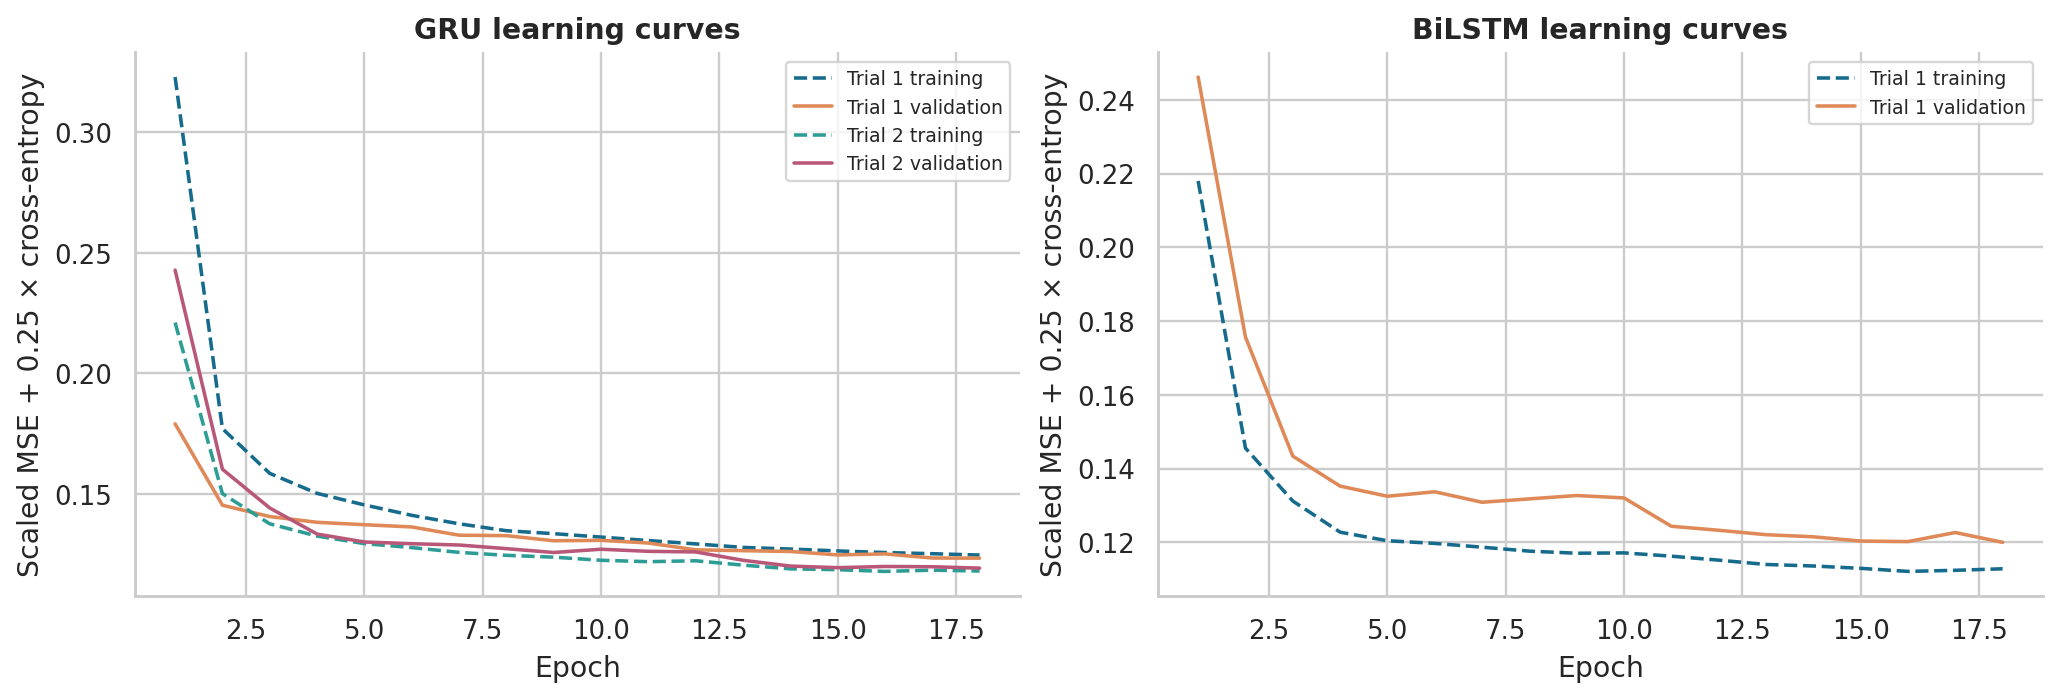

In [3]:
display(pd.read_csv(ROOT / 'reports/numpy_gd_loss.csv').iloc[[0, -1]])
display(pd.read_csv(ROOT / 'reports/dl_search.csv'))
display(Image(filename=str(ROOT / 'reports/figures/dl_learning_curves.png')))

## Common-window benchmark and error analysis

The next-window comparison uses identical road, origin and target keys. The classical models also predict 60, 90 and 120 minutes. Deep models have no accident head, so deep accident AUC is not applicable. MAPE excludes zero actual targets and reports their count.

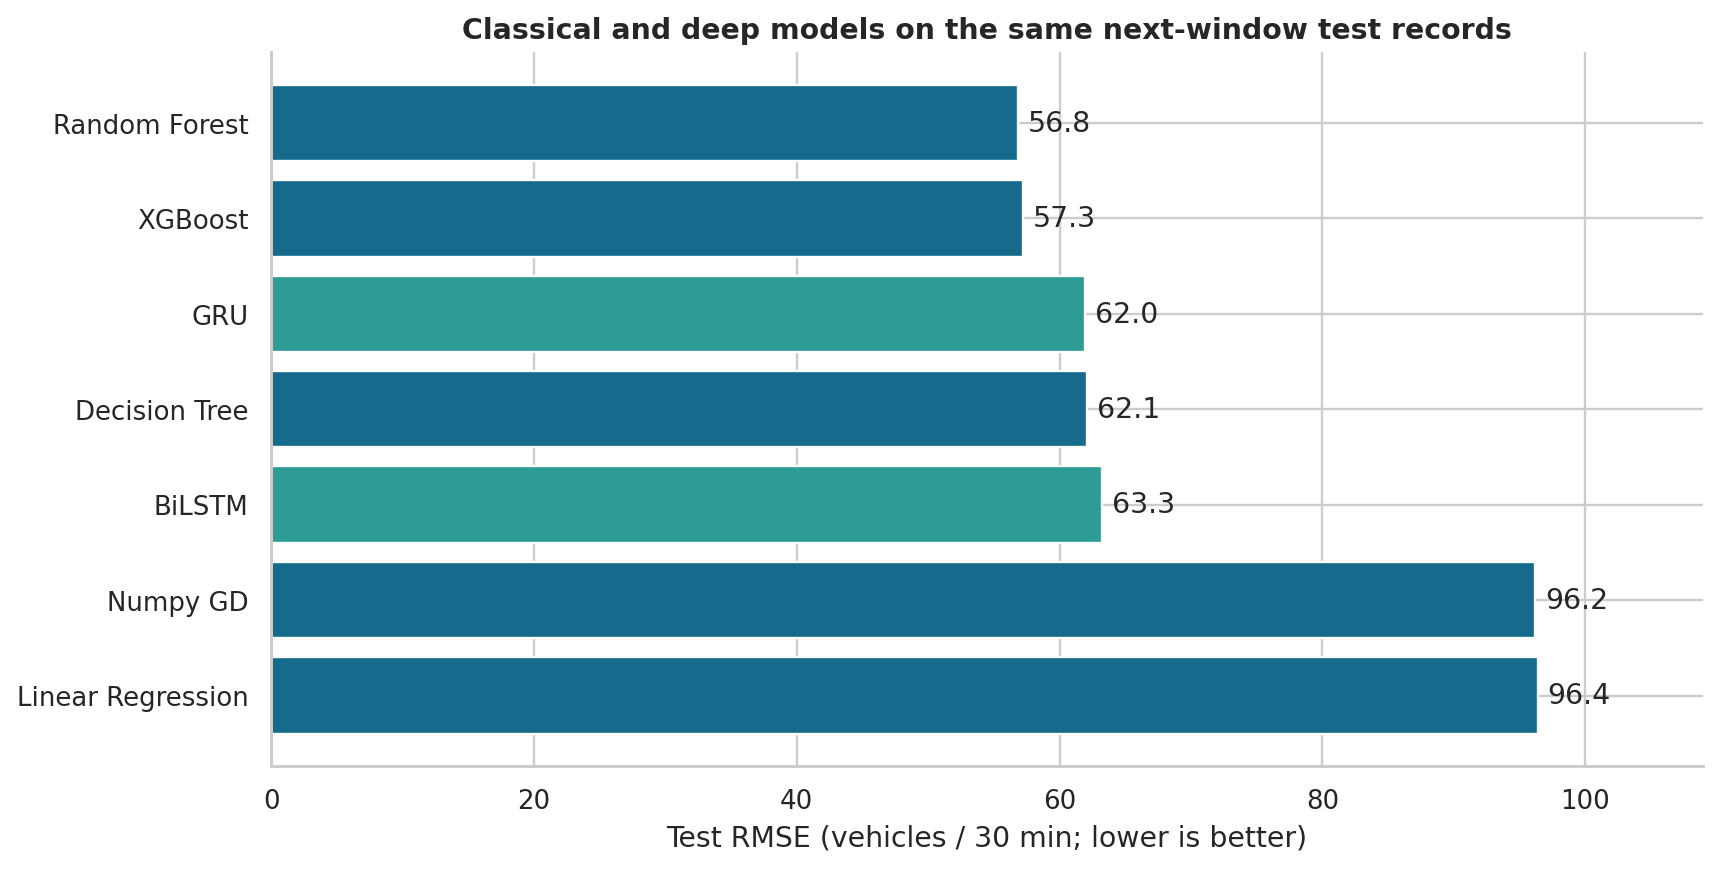

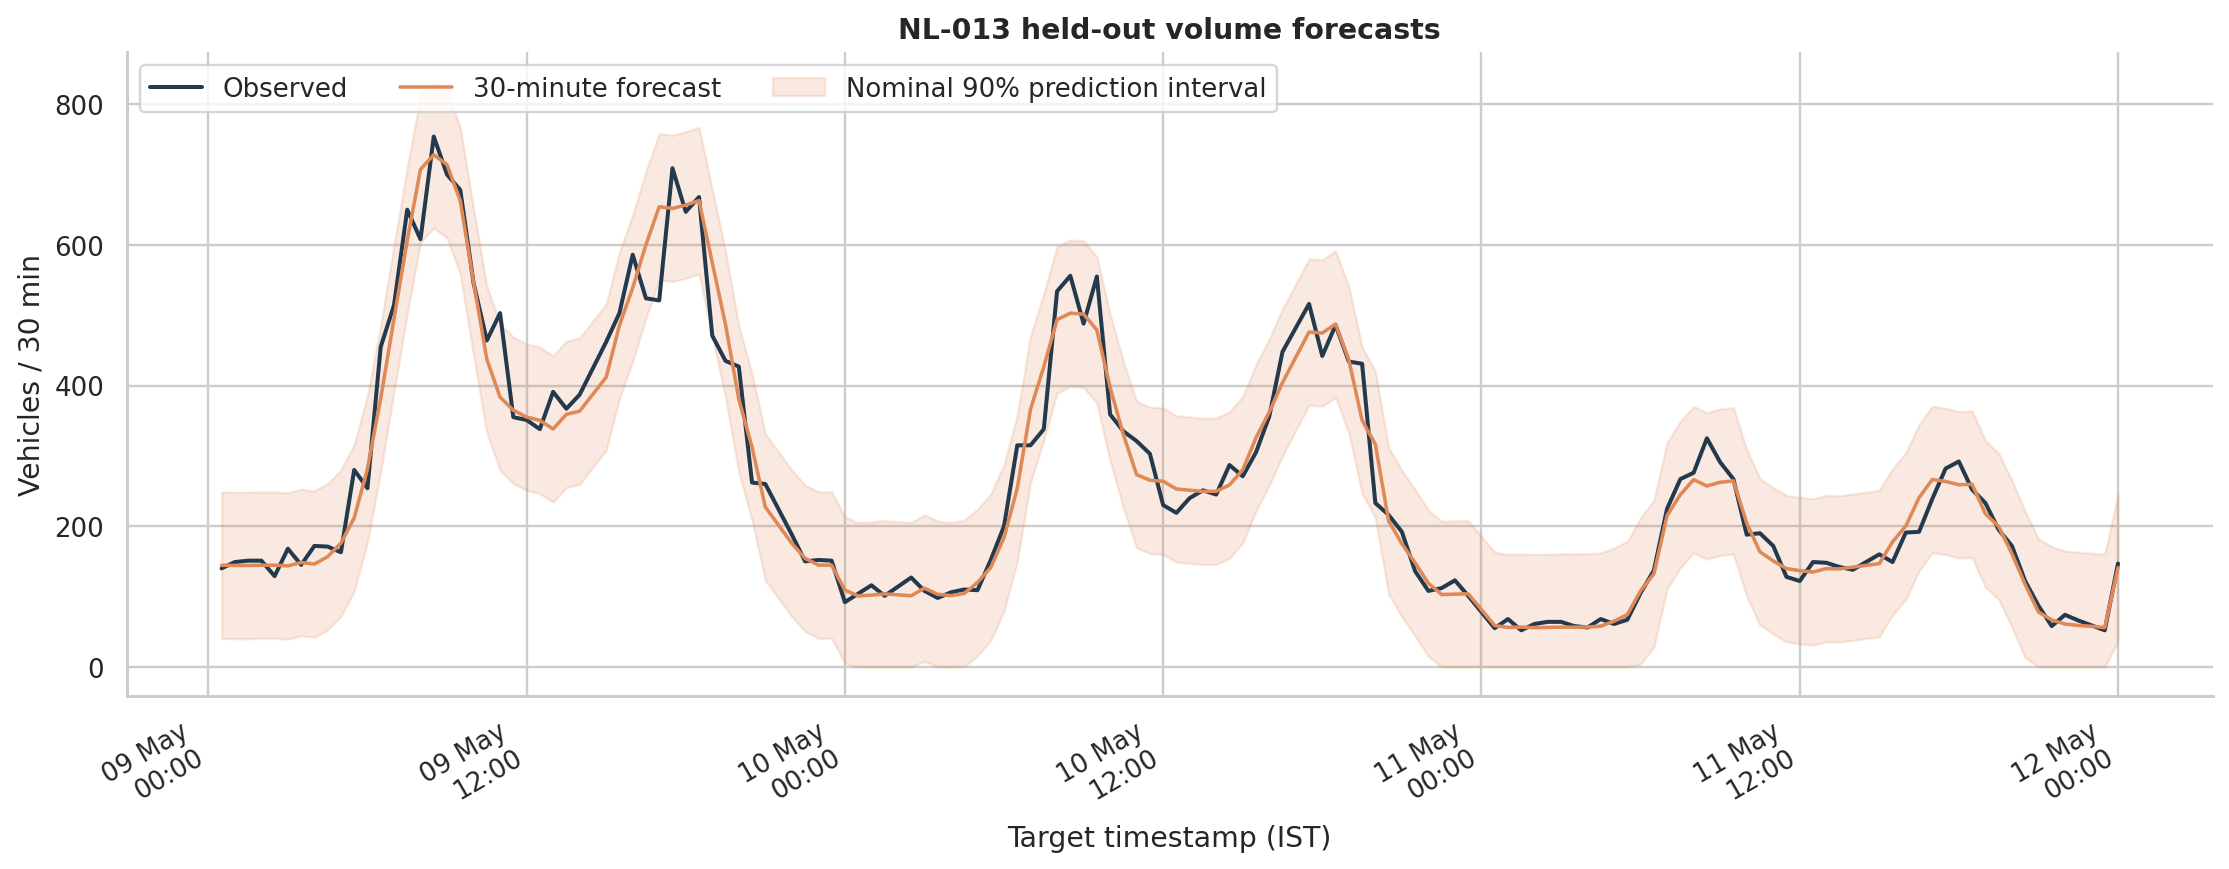

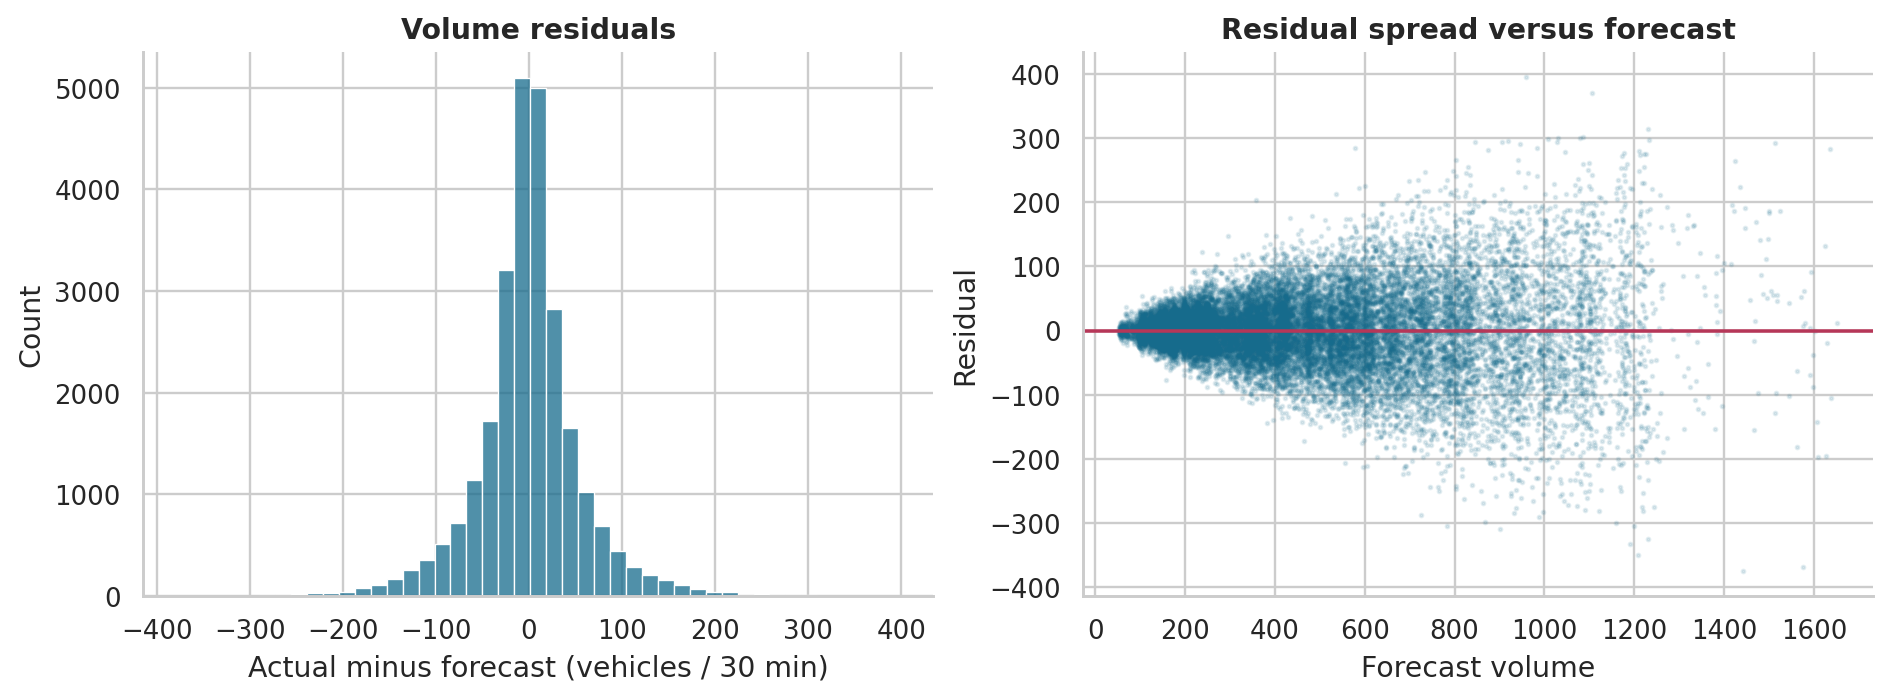

,model,task,horizon,group,value,n,precision,recall,f1,macro_f1,accuracy,roc_auc,brier,rmse,mae,mape,r2,zero_targets
0,Decision Tree,accident,1,hour,0,1059,0.000,0.000,0.000,0.497,0.990,0.546,0.010,NaN,NaN,NaN,NaN,NaN
1,Decision Tree,accident,1,hour,1,1087,0.000,0.000,0.000,0.499,0.994,0.577,0.005,NaN,NaN,NaN,NaN,NaN
2,Decision Tree,accident,1,hour,2,1078,0.000,0.000,0.000,0.499,0.995,0.502,0.005,NaN,NaN,NaN,NaN,NaN
3,Decision Tree,accident,1,hour,3,1099,0.000,0.000,0.000,0.499,0.995,0.526,0.005,NaN,NaN,NaN,NaN,NaN
4,Decision Tree,accident,1,hour,4,1091,0.000,0.000,0.000,0.497,0.988,0.533,0.012,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3355,GRU,congestion,1,weather_condition,Cloudy,5282,0.747,0.769,0.757,0.757,0.859,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3356,GRU,traffic_volume,1,weather_condition,Fog,157,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51.319,38.831,15.485,0.899,0.0
3357,GRU,congestion,1,weather_condition,Fog,157,0.361,0.367,0.363,0.363,0.892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3358,GRU,traffic_volume,1,weather_condition,Rain,1110,NaN,NaN,NaN,NaN,NaN,NaN,NaN,61.518,44.030,11.787,0.933,0.0


In [4]:
display(Image(filename=str(ROOT / 'reports/figures/model_benchmark.png')))
display(Image(filename=str(ROOT / 'reports/figures/forecast_confidence.png')))
display(Image(filename=str(ROOT / 'reports/figures/residual_analysis.png')))
display(pd.read_csv(ROOT / 'reports/error_breakdown.csv').round(3))

## Acceptance and recommendations

The acceptance file records measured results, including failures. The final report explains whether the sequence model earns its complexity. A nominal 90% interval is not a guarantee of future coverage, especially with changing traffic. Low incident recall can remain a problem even when overall accuracy is high.

In [5]:
print(json.dumps(json.loads((ROOT / 'reports/acceptance.json').read_text()), indent=2))
display(pd.read_csv(ROOT / 'reports/interval_coverage.csv').round(4))

{
  "volume_mape_percent": 9.017593410743203,
  "volume_mape_pass": true,
  "congestion_macro_f1": 0.7661392145800183,
  "congestion_f1_pass": false,
  "accident_roc_auc": 0.6074124996318874,
  "accident_auc_pass": false,
  "gru_volume_rmse": 61.9686593961435,
  "best_classical_volume_rmse": 56.8266675791982,
  "deep_beats_classical": false,
  "inference_25_roads_one_horizon_seconds": 0.3685273299997789,
  "inference_pass": true,
  "exact_test_keys_match": true,
  "test_records_horizon_1": 26124
}


,target,horizon,coverage,mean_width
0,traffic_volume,1,0.9222,207.6968
1,traffic_volume,2,0.9235,208.7072
2,traffic_volume,3,0.9242,212.0953
3,traffic_volume,4,0.9268,217.8220
4,avg_speed,1,0.9314,12.6276
5,avg_speed,2,0.9327,12.7188
6,avg_speed,3,0.9332,12.7936
7,avg_speed,4,0.9344,12.9551
8,travel_time,1,0.9123,1.9495
9,travel_time,2,0.9140,1.9595
